In [67]:
import pandas as pd
import matplotlib.pyplot as plt

In [68]:
df=pd.read_csv("Occupancy.csv")

In [69]:
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  object 
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          20560 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 1.1+ MB


## Date column

In [71]:
df["date"].head()

,date
0,2015-02-02 14:19:00
1,2015-02-02 14:19:59
2,2015-02-02 14:21:00
3,2015-02-02 14:22:00
4,2015-02-02 14:23:00


In [72]:
#convert date column to datetime
df["date"]=pd.to_datetime(df["date"])
df["date"].head()

,date
0,2015-02-02 14:19:00
1,2015-02-02 14:19:59
2,2015-02-02 14:21:00
3,2015-02-02 14:22:00
4,2015-02-02 14:23:00


In [73]:
df=df.sort_values("date")
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


In [74]:
df["date"].is_monotonic_increasing

True

In [75]:
df["date"].duplicated().sum()

np.int64(0)

In [76]:
df["date"].min()

Timestamp('2015-02-02 14:19:00')

In [77]:
df["date"].max()

Timestamp('2015-02-18 09:19:00')

In [78]:
# Count the time intervals between consecutive readings to check frequency and gaps
df["date"].diff().value_counts()

,count
date,
0 days 00:01:00,12329
0 days 00:00:59,4114
0 days 00:01:01,4114
0 days 07:08:00,1
1 days 05:15:00,1


In [79]:
# Find recording gaps longer than two minutes and show their start, end, and duration
dates = df["date"].sort_values().reset_index(drop=True)

gaps = pd.DataFrame({
    "From": dates.shift(1),
    "To": dates,
    "Duration": dates.diff()
})

gaps[gaps["Duration"] > pd.Timedelta(minutes=2)]

,From,To,Duration
2665,2015-02-04 10:43:00,2015-02-04 17:51:00,0 days 07:08:00
10808,2015-02-10 09:33:00,2015-02-11 14:48:00,1 days 05:15:00


## Data Checks

In [80]:
print("Duplicate rows:", df.duplicated().sum())

sensor_cols = [
    "Temperature", "Humidity", "Light",
    "CO2", "HumidityRatio"
]

df[sensor_cols].describe().T

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Temperature,20560.0,20.906212,1.055315,19.000000,20.200000,20.700000,21.525000,24.408333
Humidity,20560.0,27.655925,4.982154,16.745000,24.500000,27.290000,31.290000,39.500000
Light,20560.0,130.756622,210.430875,0.000000,0.000000,0.000000,301.000000,1697.250000
CO2,20560.0,690.553276,311.201281,412.750000,460.000000,565.416667,804.666667,2076.500000
HumidityRatio,20560.0,0.004228,0.000768,0.002674,0.003719,0.004292,0.004832,0.006476


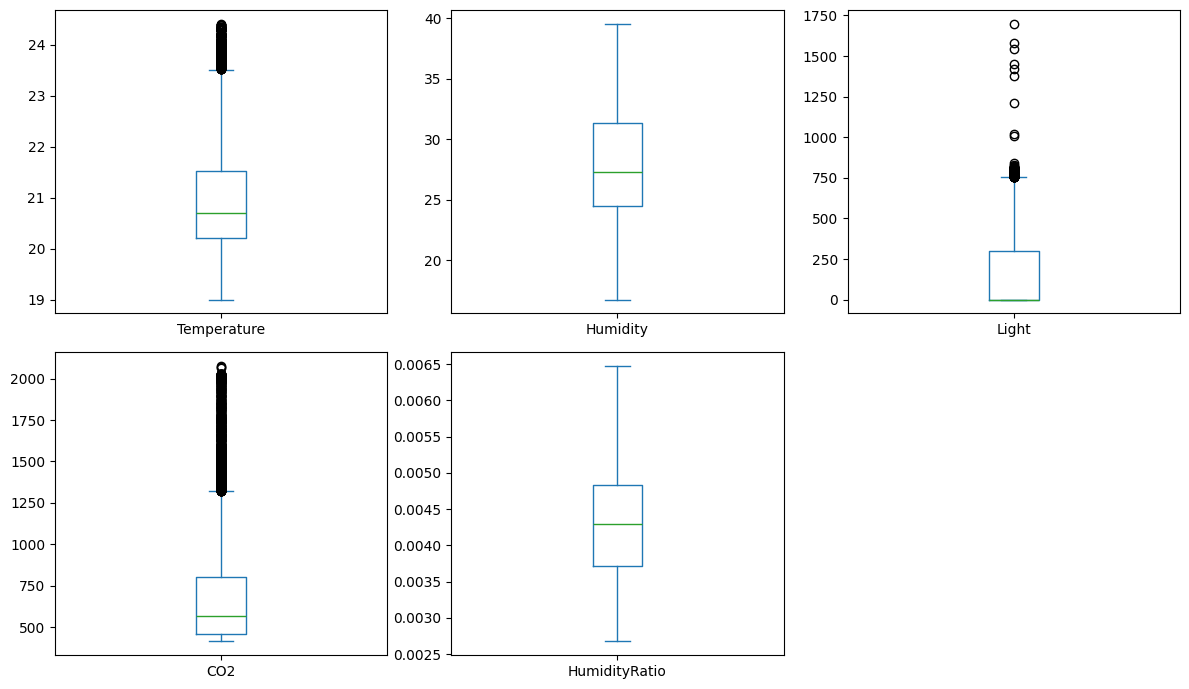

In [81]:
df[sensor_cols].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(12, 7)
)

plt.tight_layout()
plt.show()

In [82]:
for sensor in ["Light", "CO2"]:
    display(
        df.nlargest(10, sensor)[
            ["date", sensor, "Occupancy"]
        ]
    )


,date,Light,Occupancy
2602,2015-02-04 09:40:59,1697.250000,1
11947,2015-02-12 09:47:00,1581.000000,1
6496,2015-02-07 09:42:00,1546.333333,0
6497,2015-02-07 09:42:59,1451.750000,0
2601,2015-02-04 09:40:00,1419.500000,1
11946,2015-02-12 09:46:00,1380.000000,1
2603,2015-02-04 09:42:00,1209.800000,1
13389,2015-02-13 09:49:00,1021.250000,1
11948,2015-02-12 09:48:00,1010.500000,1
11949,2015-02-12 09:49:00,844.000000,1


,date,CO2,Occupancy
20111,2015-02-18 01:51:00,2076.50,0
19936,2015-02-17 22:56:00,2072.00,0
20109,2015-02-18 01:49:00,2065.75,0
9819,2015-02-09 17:05:00,2028.50,1
9838,2015-02-09 17:23:59,2028.25,1
9825,2015-02-09 17:10:59,2028.00,1
9818,2015-02-09 17:04:00,2027.50,1
9836,2015-02-09 17:22:00,2027.50,1
9834,2015-02-09 17:19:59,2026.00,1
9837,2015-02-09 17:23:00,2025.25,1


In [83]:
# Summarize daily reading counts and occupied proportions, with the weekday name
day = df["date"].dt.normalize()
check = df.groupby(day)["Occupancy"].agg(rows="count", occupied_share="mean").round(3)
check["weekday"] = check.index.day_name()
display(check)

,rows,occupied_share,weekday
date,,,
2015-02-02,581,0.349,Monday
2015-02-03,1440,0.416,Tuesday
2015-02-04,1013,0.184,Wednesday
2015-02-05,1440,0.374,Thursday
2015-02-06,1440,0.407,Friday
2015-02-07,1440,0.000,Saturday
2015-02-08,1440,0.000,Sunday
2015-02-09,1440,0.371,Monday
2015-02-10,574,0.094,Tuesday


In [84]:
# Count empty and occupied readings for each weekend date
weekend = df[df["date"].dt.dayofweek >= 5]

print(pd.crosstab(
    weekend["date"].dt.date,
    weekend["Occupancy"]
))
#No readings labeled 1 (occupied) appear on these dates.

Occupancy      0
date            
2015-02-07  1440
2015-02-08  1440
2015-02-14  1440
2015-02-15  1440


# Split the data chronologically by date into Train, Validation, and Test

In [91]:
## Split df chronologically by calendar date
day = df["date"].dt.normalize()
train  = df[day <= "2015-02-11"]
validation = df[(day >= "2015-02-12") & (day <= "2015-02-15")]
test  = df[day >= "2015-02-16"]


In [90]:
#All three chronological subsets contain both occupancy classes.
#Validation has fewer occupied readings proportionally because it includes the weekend.
print("Train:")
print(train["Occupancy"].value_counts())

print("\nValidation:")
print(validation["Occupancy"].value_counts())

print("\nTest:")
print(test["Occupancy"].value_counts())

Train:
Occupancy
0    8445
1    2915
Name: count, dtype: int64

Validation:
Occupancy
0    5022
1     738
Name: count, dtype: int64

Test:
Occupancy
0    2343
1    1097
Name: count, dtype: int64
